<a href="https://colab.research.google.com/github/vjshivani25-hub/DLAC/blob/main/skill9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Skill 9: Inference Baseline — Accuracy, mAP, Latency, Throughput and GPU Memory Measurement

## Aim
To evaluate a deep learning object detection model by measuring its baseline performance using evaluation metrics such as precision, recall, mAP, inference latency, throughput, and GPU memory utilization.

## Objectives
- Inspect the available hardware and software environment.
- Prepare an object detection model and evaluation dataset.
- Perform model inference on test images.
- Measure precision, recall, and mean Average Precision (mAP).
- Measure inference latency and throughput.
- Monitor GPU memory consumption when GPU is available.
- Visualize performance metrics and generate a final report.

In [1]:
import platform
import os
import time
import psutil
import torch

print("=" * 60)
print("SKILL 9 - ENVIRONMENT INFORMATION")
print("=" * 60)

print("Python Version:", platform.python_version())
print("Operating System:", platform.system())
print("OS Version:", platform.release())
print("PyTorch Version:", torch.__version__)

print("CPU:", platform.processor())
print("CPU Cores:", os.cpu_count())

ram_gb = psutil.virtual_memory().total / (1024 ** 3)
print(f"Total RAM: {ram_gb:.2f} GB")

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2),
        "GB"
    )
else:
    print("GPU: Not available")
    print("Inference will run using CPU.")

print("=" * 60)

SKILL 9 - ENVIRONMENT INFORMATION
Python Version: 3.13.18
Operating System: Linux
OS Version: 6.6.159+
PyTorch Version: 2.14.1+cpu
CPU: x86_64
CPU Cores: 2
Total RAM: 12.67 GB
CUDA Available: False
GPU: Not available
Inference will run using CPU.


In [2]:
import os

project_dir = "/content/Skill9_Inference_Baseline"

folders = [
    "data",
    "models",
    "results",
    "graphs",
    "reports"
]

for folder in folders:
    path = os.path.join(project_dir, folder)
    os.makedirs(path, exist_ok=True)
    print("Created:", path)

print("\nProject workspace created successfully!")

Created: /content/Skill9_Inference_Baseline/data
Created: /content/Skill9_Inference_Baseline/models
Created: /content/Skill9_Inference_Baseline/results
Created: /content/Skill9_Inference_Baseline/graphs
Created: /content/Skill9_Inference_Baseline/reports

Project workspace created successfully!


In [3]:
for root, dirs, files in os.walk(project_dir):
    level = root.replace(project_dir, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

Skill9_Inference_Baseline/
    data/
    reports/
    models/
    results/
    graphs/


In [4]:
import numpy as np
import torch
from PIL import Image, ImageDraw
from torch.utils.data import Dataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

IMG_SIZE = 64
NUM_CLASSES = 3

class_names = ["Person", "Car", "Bicycle"]

class SyntheticDetectionDataset(Dataset):
    def __init__(self, num_images=500):
        self.num_images = num_images
        self.images = []
        self.labels = []
        self.boxes = []

        for i in range(num_images):
            image = Image.new("RGB", (IMG_SIZE, IMG_SIZE), (240, 240, 240))
            draw = ImageDraw.Draw(image)

            class_id = np.random.randint(0, NUM_CLASSES)

            # Random object position and size
            x1 = np.random.randint(8, 20)
            y1 = np.random.randint(8, 20)
            x2 = np.random.randint(44, 57)
            y2 = np.random.randint(44, 57)

            color = tuple(np.random.randint(40, 220, size=3).tolist())

            if class_id == 0:
                # Person: head, body, legs
                head_r = max(4, (x2 - x1) // 6)
                head_x = (x1 + x2) // 2
                head_y = y1 + head_r + 2

                draw.ellipse(
                    [head_x-head_r, head_y-head_r,
                     head_x+head_r, head_y+head_r],
                    fill=color
                )

                body_top = head_y + head_r
                body_bottom = y2 - 10

                draw.rectangle(
                    [head_x-5, body_top, head_x+5, body_bottom],
                    fill=color
                )

                draw.line(
                    [head_x, body_bottom, x1+5, y2],
                    fill=color, width=4
                )

                draw.line(
                    [head_x, body_bottom, x2-5, y2],
                    fill=color, width=4
                )

            elif class_id == 1:
                # Car: body and wheels
                draw.rectangle(
                    [x1, y1+10, x2, y2-8],
                    fill=color
                )

                draw.rectangle(
                    [x1+8, y1+3, x2-8, y1+13],
                    fill=color
                )

                wheel_r = 5

                draw.ellipse(
                    [x1+5, y2-10, x1+5+wheel_r*2, y2-10+wheel_r*2],
                    fill=(30, 30, 30)
                )

                draw.ellipse(
                    [x2-15, y2-10, x2-15+wheel_r*2, y2-10+wheel_r*2],
                    fill=(30, 30, 30)
                )

            else:
                # Bicycle: two wheels and frame
                wheel_r = 10

                left_c = (x1+wheel_r, y2-wheel_r)
                right_c = (x2-wheel_r, y2-wheel_r)

                draw.ellipse(
                    [left_c[0]-wheel_r, left_c[1]-wheel_r,
                     left_c[0]+wheel_r, left_c[1]+wheel_r],
                    outline=(30, 30, 30), width=3
                )

                draw.ellipse(
                    [right_c[0]-wheel_r, right_c[1]-wheel_r,
                     right_c[0]+wheel_r, right_c[1]+wheel_r],
                    outline=(30, 30, 30), width=3
                )

                draw.line(
                    [left_c, (x1+x2)//2, y1+15, right_c],
                    fill=color, width=3
                )

                draw.line(
                    [left_c, right_c],
                    fill=color, width=3
                )

                draw.line(
                    [(x1+x2)//2, y1+15, (x1+x2)//2+5, y1+8],
                    fill=(30, 30, 30), width=3
                )

            # Convert image to tensor [C, H, W]
            image_array = np.array(image, dtype=np.float32) / 255.0
            image_tensor = torch.tensor(image_array).permute(2, 0, 1)

            # Normalized bounding box
            box = torch.tensor([
                x1 / IMG_SIZE,
                y1 / IMG_SIZE,
                x2 / IMG_SIZE,
                y2 / IMG_SIZE
            ], dtype=torch.float32)

            self.images.append(image_tensor)
            self.labels.append(class_id)
            self.boxes.append(box)

    def __len__(self):
        return self.num_images

    def __getitem__(self, index):
        return (
            self.images[index],
            torch.tensor(self.labels[index], dtype=torch.long),
            self.boxes[index]
        )


# Generate training and testing datasets
train_dataset = SyntheticDetectionDataset(num_images=500)
test_dataset = SyntheticDetectionDataset(num_images=100)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Sample class:", class_names[train_dataset[0][1].item()])
print("Sample bounding box:", train_dataset[0][2])


Training images: 500
Testing images: 100
Image shape: torch.Size([3, 64, 64])
Sample class: Bicycle
Sample bounding box: tensor([0.1719, 0.2812, 0.7969, 0.8750])


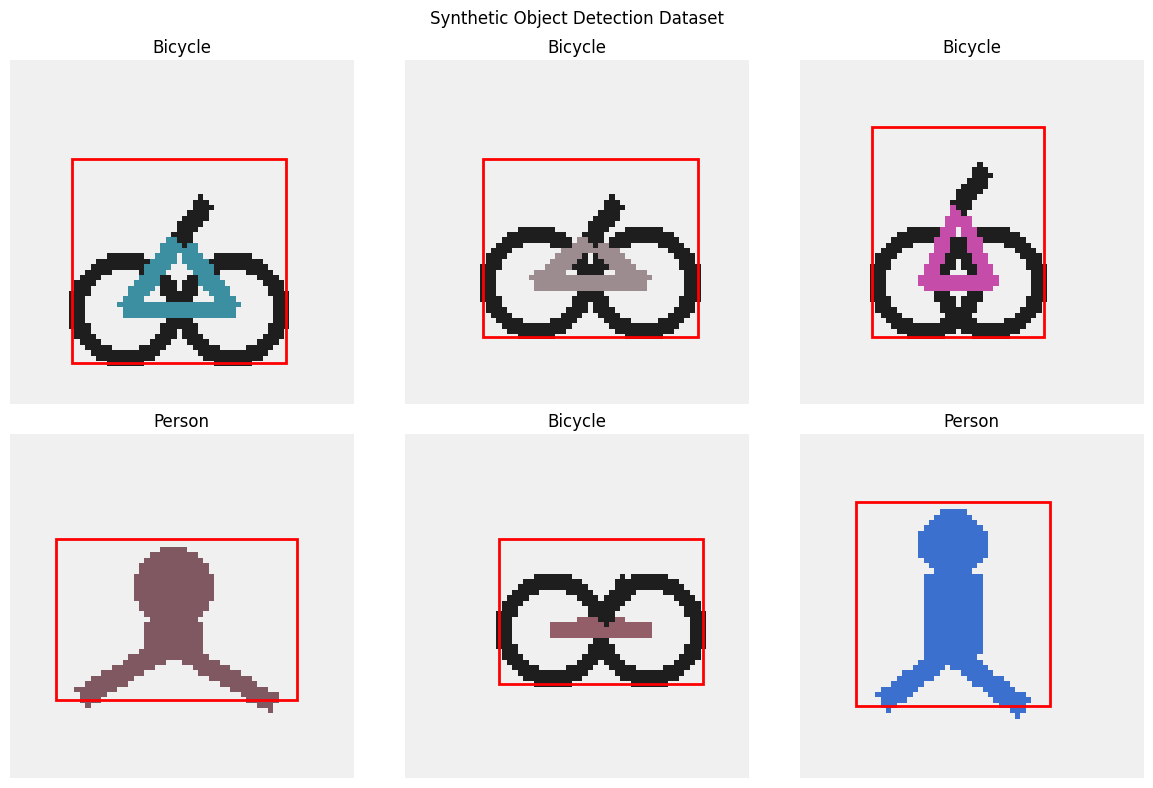

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    image, label, box = train_dataset[i]

    image_np = image.permute(1, 2, 0).numpy()

    ax.imshow(image_np)
    ax.set_title(class_names[label.item()])

    # Convert normalized coordinates into image coordinates
    x1, y1, x2, y2 = box.numpy()

    x1 *= IMG_SIZE
    y1 *= IMG_SIZE
    x2 *= IMG_SIZE
    y2 *= IMG_SIZE

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)
    ax.axis("off")

plt.suptitle("Synthetic Object Detection Dataset")
plt.tight_layout()
plt.show()

In [6]:
from collections import Counter

train_labels = [label.item() for _, label, _ in train_dataset]
test_labels = [label.item() for _, label, _ in test_dataset]

train_distribution = Counter(train_labels)
test_distribution = Counter(test_labels)

print("=" * 50)
print("DATASET VALIDATION")
print("=" * 50)

print("\nTraining Dataset:")
for class_id, class_name in enumerate(class_names):
    print(f"{class_name}: {train_distribution[class_id]} images")

print("\nTesting Dataset:")
for class_id, class_name in enumerate(class_names):
    print(f"{class_name}: {test_distribution[class_id]} images")

print("\nTotal training images:", len(train_dataset))
print("Total testing images:", len(test_dataset))

print("\nImage dimensions:", train_dataset[0][0].shape)
print("Number of classes:", NUM_CLASSES)

# Check bounding boxes
valid_boxes = all(
    torch.all(box >= 0) and torch.all(box <= 1)
    and box[0] < box[2] and box[1] < box[3]
    for _, _, box in train_dataset
)

print("Training bounding boxes valid:", valid_boxes)

valid_test_boxes = all(
    torch.all(box >= 0) and torch.all(box <= 1)
    and box[0] < box[2] and box[1] < box[3]
    for _, _, box in test_dataset
)

print("Testing bounding boxes valid:", valid_test_boxes)

print("=" * 50)

DATASET VALIDATION

Training Dataset:
Person: 163 images
Car: 178 images
Bicycle: 159 images

Testing Dataset:
Person: 32 images
Car: 33 images
Bicycle: 35 images

Total training images: 500
Total testing images: 100

Image dimensions: torch.Size([3, 64, 64])
Number of classes: 3
Training bounding boxes valid: True
Testing bounding boxes valid: True


In [7]:
import torch
import torch.nn as nn

class CNNDetectionModel(nn.Module):
    def __init__(self, num_classes=3):
        super(CNNDetectionModel, self).__init__()

        # Feature extraction layers
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Shared feature layer
        self.shared = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 128),
            nn.ReLU()
        )

        # Classification head
        self.classification_head = nn.Linear(128, num_classes)

        # Bounding box regression head
        self.bbox_head = nn.Sequential(
            nn.Linear(128, 4),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.features(x)
        shared_features = self.shared(features)

        class_logits = self.classification_head(shared_features)
        predicted_boxes = self.bbox_head(shared_features)

        return class_logits, predicted_boxes


# Create model
model = CNNDetectionModel(num_classes=NUM_CLASSES)

# Select available device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Model created successfully!")
print("Device:", device)
print(model)

Model created successfully!
Device: cpu
CNNDetectionModel(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (shared): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=128, bias=True)
    (2): ReLU()
  )
  (classification_head): Linear(in_features=128, out_features=3, bias=True)
  (bbox_head): Sequential(
    (0): Linear(in_features=128, out_features=4, bias=True)
    (1): Sigmoid()
  )
)


In [8]:
from torch.utils.data import DataLoader
import torch.optim as optim

# Data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# Loss functions
classification_loss_fn = nn.CrossEntropyLoss()
bbox_loss_fn = nn.MSELoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training configuration
NUM_EPOCHS = 15

classification_losses = []
bbox_losses = []
total_losses = []

print("=" * 60)
print("CNN MODEL TRAINING")
print("=" * 60)

for epoch in range(NUM_EPOCHS):

    model.train()

    total_class_loss = 0
    total_bbox_loss = 0
    total_loss = 0

    for images, labels, boxes in train_loader:

        images = images.to(device)
        labels = labels.to(device)
        boxes = boxes.to(device)

        # Forward pass
        class_predictions, bbox_predictions = model(images)

        # Calculate losses
        class_loss = classification_loss_fn(
            class_predictions, labels
        )

        bbox_loss = bbox_loss_fn(
            bbox_predictions, boxes
        )

        # Combined loss
        loss = class_loss + bbox_loss

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_class_loss += class_loss.item()
        total_bbox_loss += bbox_loss.item()
        total_loss += loss.item()

    # Average losses
    batches = len(train_loader)

    avg_class_loss = total_class_loss / batches
    avg_bbox_loss = total_bbox_loss / batches
    avg_total_loss = total_loss / batches

    classification_losses.append(avg_class_loss)
    bbox_losses.append(avg_bbox_loss)
    total_losses.append(avg_total_loss)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Classification Loss: {avg_class_loss:.4f} | "
        f"BBox Loss: {avg_bbox_loss:.4f} | "
        f"Total Loss: {avg_total_loss:.4f}"
    )

print("\nTraining completed successfully!")

CNN MODEL TRAINING
Epoch [1/15] | Classification Loss: 1.0965 | BBox Loss: 0.0713 | Total Loss: 1.1678
Epoch [2/15] | Classification Loss: 1.0525 | BBox Loss: 0.0170 | Total Loss: 1.0695
Epoch [3/15] | Classification Loss: 0.8183 | BBox Loss: 0.0058 | Total Loss: 0.8241
Epoch [4/15] | Classification Loss: 0.4601 | BBox Loss: 0.0072 | Total Loss: 0.4673
Epoch [5/15] | Classification Loss: 0.1892 | BBox Loss: 0.0041 | Total Loss: 0.1932
Epoch [6/15] | Classification Loss: 0.0692 | BBox Loss: 0.0035 | Total Loss: 0.0727
Epoch [7/15] | Classification Loss: 0.0262 | BBox Loss: 0.0034 | Total Loss: 0.0297
Epoch [8/15] | Classification Loss: 0.0148 | BBox Loss: 0.0035 | Total Loss: 0.0183
Epoch [9/15] | Classification Loss: 0.0093 | BBox Loss: 0.0035 | Total Loss: 0.0127
Epoch [10/15] | Classification Loss: 0.0078 | BBox Loss: 0.0034 | Total Loss: 0.0112
Epoch [11/15] | Classification Loss: 0.0048 | BBox Loss: 0.0034 | Total Loss: 0.0082
Epoch [12/15] | Classification Loss: 0.0037 | BBox Loss

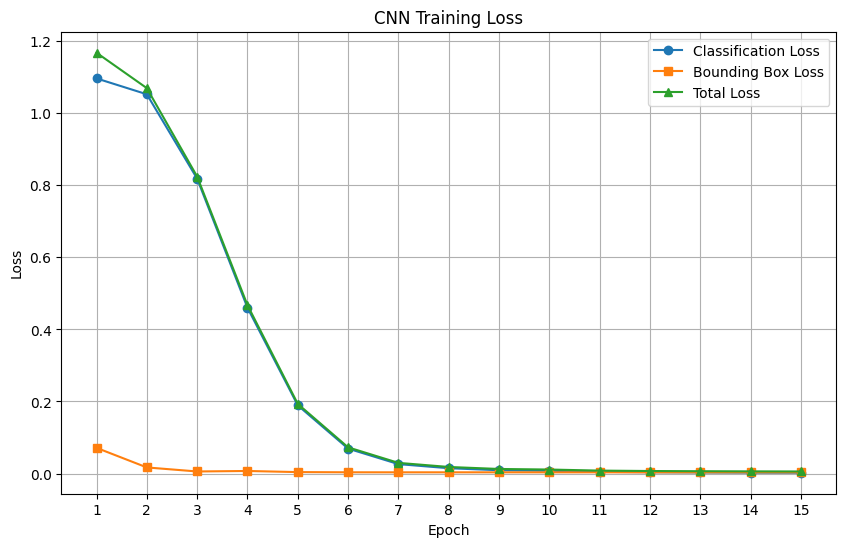

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    classification_losses,
    marker="o",
    label="Classification Loss"
)

plt.plot(
    bbox_losses,
    marker="s",
    label="Bounding Box Loss"
)

plt.plot(
    total_losses,
    marker="^",
    label="Total Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training Loss")
plt.legend()
plt.grid(True)

plt.xticks(range(NUM_EPOCHS), range(1, NUM_EPOCHS + 1))

plt.show()

In [10]:
import os
import torch

model_path = os.path.join(
    project_dir,
    "models",
    "skill9_cnn_detection_model.pth"
)

torch.save(model.state_dict(), model_path)

print("Model saved successfully!")
print("Saved location:", model_path)

print(
    "Model file size:",
    round(os.path.getsize(model_path) / 1024, 2),
    "KB"
)

Model saved successfully!
Saved location: /content/Skill9_Inference_Baseline/models/skill9_cnn_detection_model.pth
Model file size: 133.52 KB


In [11]:
from torch.utils.data import DataLoader
import torch
import time

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

model.eval()

all_true_labels = []
all_pred_labels = []

all_true_boxes = []
all_pred_boxes = []

inference_outputs = []

print("Starting test-set inference...")

with torch.inference_mode():

    for images, labels, boxes in test_loader:

        images = images.to(device)

        # Model predictions
        class_predictions, bbox_predictions = model(images)

        # Predicted class
        predicted_classes = torch.argmax(
            class_predictions,
            dim=1
        )

        # Store results
        all_true_labels.extend(labels.numpy())
        all_pred_labels.extend(predicted_classes.cpu().numpy())

        all_true_boxes.extend(boxes.numpy())
        all_pred_boxes.extend(bbox_predictions.cpu().numpy())

        inference_outputs.append(
            class_predictions.cpu()
        )

print("\nInference completed successfully!")

print("Total test images:", len(all_true_labels))
print("Actual labels collected:", len(all_true_labels))
print("Predicted labels collected:", len(all_pred_labels))
print("Actual bounding boxes:", len(all_true_boxes))
print("Predicted bounding boxes:", len(all_pred_boxes))

Starting test-set inference...

Inference completed successfully!
Total test images: 100
Actual labels collected: 100
Predicted labels collected: 100
Actual bounding boxes: 100
Predicted bounding boxes: 100


In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    all_true_labels,
    all_pred_labels
)

correct_predictions = sum(
    actual == predicted
    for actual, predicted in zip(
        all_true_labels,
        all_pred_labels
    )
)

total_predictions = len(all_true_labels)

print("=" * 50)
print("BASELINE CLASSIFICATION ACCURACY")
print("=" * 50)

print("Correct Predictions:", correct_predictions)
print("Total Predictions:", total_predictions)

print(f"Accuracy: {accuracy * 100:.2f}%")

print("=" * 50)

BASELINE CLASSIFICATION ACCURACY
Correct Predictions: 99
Total Predictions: 100
Accuracy: 99.00%


In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

precision = precision_score(
    all_true_labels,
    all_pred_labels,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_true_labels,
    all_pred_labels,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_true_labels,
    all_pred_labels,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("CLASSIFICATION PERFORMANCE METRICS")
print("=" * 60)

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")

print("\nDetailed Classification Report:\n")

print(
    classification_report(
        all_true_labels,
        all_pred_labels,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

CLASSIFICATION PERFORMANCE METRICS
Accuracy  : 99.00%
Precision : 99.02%
Recall    : 98.96%
F1-Score  : 98.97%

Detailed Classification Report:

              precision    recall  f1-score   support

      Person       1.00      0.97      0.98        32
         Car       0.97      1.00      0.99        33
     Bicycle       1.00      1.00      1.00        35

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100



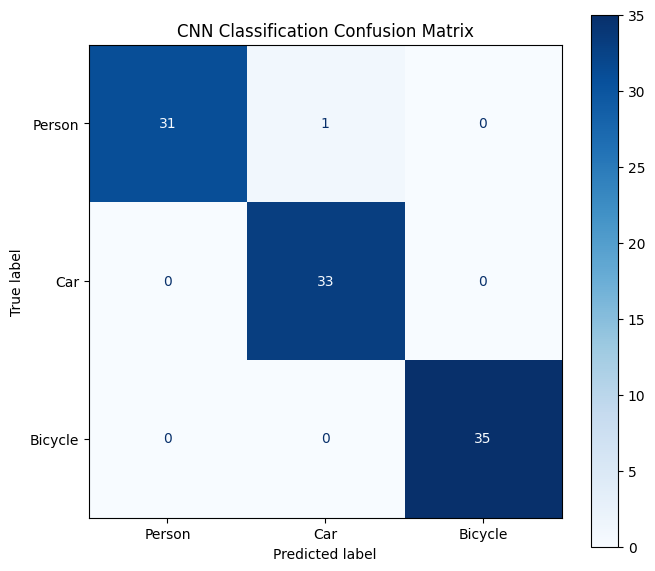

Confusion Matrix:
[[31  1  0]
 [ 0 33  0]
 [ 0  0 35]]


In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_true_labels,
    all_pred_labels,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("CNN Classification Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

In [15]:
import numpy as np

def calculate_iou(box1, box2):
    """
    Calculate Intersection over Union for two boxes.

    Box format:
    [x_min, y_min, x_max, y_max]
    """

    # Intersection coordinates
    x_left = max(box1[0], box2[0])
    y_top = max(box1[1], box2[1])

    x_right = min(box1[2], box2[2])
    y_bottom = min(box1[3], box2[3])

    # Intersection area
    intersection_width = max(0, x_right - x_left)
    intersection_height = max(0, y_bottom - y_top)

    intersection_area = (
        intersection_width * intersection_height
    )

    # Areas of individual boxes
    area1 = max(0, box1[2] - box1[0]) * max(
        0, box1[3] - box1[1]
    )

    area2 = max(0, box2[2] - box2[0]) * max(
        0, box2[3] - box2[1]
    )

    # Union area
    union_area = area1 + area2 - intersection_area

    if union_area == 0:
        return 0.0

    return intersection_area / union_area


# Calculate IoU for all test images
iou_scores = []

for actual_box, predicted_box in zip(
    all_true_boxes,
    all_pred_boxes
):
    iou = calculate_iou(actual_box, predicted_box)
    iou_scores.append(iou)

iou_scores = np.array(iou_scores)

mean_iou = np.mean(iou_scores)

print("=" * 50)
print("BOUNDING BOX EVALUATION")
print("=" * 50)

print(f"Mean IoU: {mean_iou:.4f}")
print(f"Mean IoU (%): {mean_iou * 100:.2f}%")

print(
    f"Images with IoU >= 0.50: "
    f"{np.sum(iou_scores >= 0.50)} / {len(iou_scores)}"
)

print(
    f"Images with IoU >= 0.75: "
    f"{np.sum(iou_scores >= 0.75)} / {len(iou_scores)}"
)

print("=" * 50)

BOUNDING BOX EVALUATION
Mean IoU: 0.7260
Mean IoU (%): 72.60%
Images with IoU >= 0.50: 100 / 100
Images with IoU >= 0.75: 36 / 100


In [17]:
import numpy as np
import torch

# Convert data into NumPy arrays
all_logits = torch.cat(inference_outputs, dim=0)

all_confidences = torch.softmax(
    all_logits, dim=1
).numpy()

all_true_labels_np = np.asarray(all_true_labels)
all_pred_labels_np = np.asarray(all_pred_labels)

all_true_boxes_np = np.asarray(all_true_boxes)
all_pred_boxes_np = np.asarray(all_pred_boxes)


def calculate_average_precision(
    true_positive_flags,
    confidence_scores,
    total_ground_truths
):

    if total_ground_truths == 0:
        return 0.0

    # FIX: Convert Python lists into NumPy arrays
    true_positive_flags = np.asarray(
        true_positive_flags, dtype=np.float32
    )

    confidence_scores = np.asarray(
        confidence_scores, dtype=np.float32
    )

    if len(confidence_scores) == 0:
        return 0.0

    # Sort by confidence in descending order
    order = np.argsort(-confidence_scores)

    tp = true_positive_flags[order]
    fp = 1 - tp

    cumulative_tp = np.cumsum(tp)
    cumulative_fp = np.cumsum(fp)

    recall_curve = cumulative_tp / total_ground_truths

    precision_curve = cumulative_tp / (
        cumulative_tp + cumulative_fp + 1e-10
    )

    # Precision envelope
    precision_curve = np.maximum.accumulate(
        precision_curve[::-1]
    )[::-1]

    # 101-point interpolated precision
    recall_points = np.linspace(0, 1, 101)

    interpolated_precision = []

    for recall_point in recall_points:

        valid = recall_curve >= recall_point

        if np.any(valid):
            interpolated_precision.append(
                np.max(precision_curve[valid])
            )
        else:
            interpolated_precision.append(0.0)

    return float(np.mean(interpolated_precision))


def calculate_map(iou_threshold=0.50):

    class_aps = {}

    for class_id, class_name in enumerate(class_names):

        total_ground_truths = np.sum(
            all_true_labels_np == class_id
        )

        candidate_indices = np.where(
            all_pred_labels_np == class_id
        )[0]

        confidence_scores = []
        true_positive_flags = []

        for idx in candidate_indices:

            confidence = float(
                all_confidences[idx, class_id]
            )

            iou = calculate_iou(
                all_true_boxes_np[idx],
                all_pred_boxes_np[idx]
            )

            is_correct = (
                all_true_labels_np[idx] == class_id
                and iou >= iou_threshold
            )

            confidence_scores.append(confidence)

            true_positive_flags.append(
                1 if is_correct else 0
            )

        ap = calculate_average_precision(
            true_positive_flags,
            confidence_scores,
            total_ground_truths
        )

        class_aps[class_name] = ap

    mean_ap = np.mean(list(class_aps.values()))

    return class_aps, mean_ap


# Calculate mAP@0.50
aps_50, map_50 = calculate_map(0.50)

# Calculate mAP@0.75
aps_75, map_75 = calculate_map(0.75)

# Calculate mAP@0.50:0.95
iou_thresholds = np.arange(0.50, 0.96, 0.05)

map_values = []

for threshold in iou_thresholds:

    _, current_map = calculate_map(
        float(threshold)
    )

    map_values.append(current_map)

map_50_95 = np.mean(map_values)


# Display results
print("=" * 60)
print("MEAN AVERAGE PRECISION (mAP) RESULTS")
print("=" * 60)

print("\nAP per class at IoU 0.50:")

for class_name, ap in aps_50.items():
    print(f"{class_name}: {ap * 100:.2f}%")

print(f"\nmAP@0.50: {map_50 * 100:.2f}%")
print(f"mAP@0.75: {map_75 * 100:.2f}%")
print(f"mAP@0.50:0.95: {map_50_95 * 100:.2f}%")

print("\nIoU thresholds:", iou_thresholds)
print("=" * 60)

MEAN AVERAGE PRECISION (mAP) RESULTS

AP per class at IoU 0.50:
Person: 96.04%
Car: 100.00%
Bicycle: 100.00%

mAP@0.50: 98.68%
mAP@0.75: 16.90%
mAP@0.50:0.95: 43.91%

IoU thresholds: [0.5  0.55 0.6  0.65 0.7  0.75 0.8  0.85 0.9  0.95]


In [18]:
import time
import torch
import numpy as np

model.eval()

# Identify the device
device = next(model.parameters()).device
print("Inference device:", device)

# Warm-up
with torch.inference_mode():
    for images, labels, boxes in test_loader:
        images = images.to(device)
        _ = model(images)
        break

if device.type == "cuda":
    torch.cuda.synchronize()

# Latency measurement
total_images = 0
total_batches = 0
total_time = 0.0

batch_latencies = []
image_latencies = []

NUM_RUNS = 5

with torch.inference_mode():

    for run in range(NUM_RUNS):

        run_images = 0

        for images, labels, boxes in test_loader:

            images = images.to(device)

            if device.type == "cuda":
                torch.cuda.synchronize()

            start_time = time.perf_counter()

            class_output, bbox_output = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()

            end_time = time.perf_counter()

            elapsed = end_time - start_time

            batch_size = images.size(0)

            batch_latencies.append(elapsed * 1000)
            image_latencies.append((elapsed * 1000) / batch_size)

            total_time += elapsed
            total_images += batch_size
            total_batches += 1
            run_images += batch_size

# Calculate results
avg_batch_latency = np.mean(batch_latencies)
avg_image_latency = np.mean(image_latencies)
total_inference_time = total_time

print("\n========== INFERENCE LATENCY RESULTS ==========")
print(f"Number of runs: {NUM_RUNS}")
print(f"Total images processed: {total_images}")
print(f"Total batches processed: {total_batches}")
print(f"Average batch latency: {avg_batch_latency:.4f} ms")
print(f"Average per-image latency: {avg_image_latency:.4f} ms")
print(f"Total inference time: {total_inference_time:.4f} seconds")
print("=============================================")

Inference device: cpu

========== INFERENCE LATENCY RESULTS ==========
Number of runs: 5
Total images processed: 500
Total batches processed: 20
Average batch latency: 71.9632 ms
Average per-image latency: 2.9287 ms
Total inference time: 1.4393 seconds


In [19]:
import time
import torch
import numpy as np

model.eval()

# Warm-up
warmup_batches = 3

with torch.inference_mode():
    for i, (images, labels, boxes) in enumerate(test_loader):
        images = images.to(device)

        _ = model(images)

        if i + 1 >= warmup_batches:
            break

# Synchronize GPU if available
if device.type == "cuda":
    torch.cuda.synchronize()

# Benchmark
latency_times = []
total_images_processed = 0

benchmark_repeats = 10

with torch.inference_mode():
    for repeat in range(benchmark_repeats):
        for images, labels, boxes in test_loader:

            images = images.to(device)

            if device.type == "cuda":
                torch.cuda.synchronize()

            start_time = time.perf_counter()

            _ = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()

            end_time = time.perf_counter()

            batch_latency = (end_time - start_time) * 1000

            latency_times.append(batch_latency)

            total_images_processed += images.size(0)

# Calculate metrics
average_batch_latency = np.mean(latency_times)
average_image_latency = average_batch_latency / 32
median_batch_latency = np.median(latency_times)
min_batch_latency = np.min(latency_times)
max_batch_latency = np.max(latency_times)

print("=" * 50)
print("INFERENCE LATENCY BENCHMARK")
print("=" * 50)

print(f"Device: {device}")
print(f"Number of benchmark runs: {benchmark_repeats}")
print(f"Total batches measured: {len(latency_times)}")
print(f"Average batch latency: {average_batch_latency:.4f} ms")
print(f"Median batch latency: {median_batch_latency:.4f} ms")
print(f"Minimum batch latency: {min_batch_latency:.4f} ms")
print(f"Maximum batch latency: {max_batch_latency:.4f} ms")
print(f"Average latency per image: {average_image_latency:.4f} ms")

INFERENCE LATENCY BENCHMARK
Device: cpu
Number of benchmark runs: 10
Total batches measured: 40
Average batch latency: 161.8998 ms
Median batch latency: 153.5005 ms
Minimum batch latency: 12.6273 ms
Maximum batch latency: 404.8902 ms
Average latency per image: 5.0594 ms


In [20]:
import time
import torch

model.eval()

# Warm-up
with torch.inference_mode():
    for i, (images, labels, boxes) in enumerate(test_loader):
        images = images.to(device)
        _ = model(images)

        if i >= 2:
            break

if device.type == "cuda":
    torch.cuda.synchronize()

# Throughput benchmark
total_images = 0

benchmark_repeats = 10

start_time = time.perf_counter()

with torch.inference_mode():
    for repeat in range(benchmark_repeats):

        for images, labels, boxes in test_loader:

            images = images.to(device)

            _ = model(images)

            total_images += images.size(0)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.perf_counter()

total_time_seconds = end_time - start_time

throughput = total_images / total_time_seconds

print("=" * 50)
print("THROUGHPUT BENCHMARK")
print("=" * 50)

print(f"Device: {device}")
print(f"Benchmark repetitions: {benchmark_repeats}")
print(f"Total images processed: {total_images}")
print(f"Total inference time: {total_time_seconds:.4f} seconds")
print(f"Throughput: {throughput:.2f} images/second")

THROUGHPUT BENCHMARK
Device: cpu
Benchmark repetitions: 10
Total images processed: 1000
Total inference time: 3.2690 seconds
Throughput: 305.90 images/second


In [21]:
import torch

print("=" * 50)
print("GPU MEMORY BENCHMARK")
print("=" * 50)

if torch.cuda.is_available():

    # Reset memory statistics
    torch.cuda.reset_peak_memory_stats()

    model.eval()

    with torch.inference_mode():

        for images, labels, boxes in test_loader:

            images = images.to(device)

            _ = model(images)

    torch.cuda.synchronize()

    allocated_memory = torch.cuda.memory_allocated() / (1024 ** 2)
    reserved_memory = torch.cuda.memory_reserved() / (1024 ** 2)

    peak_allocated_memory = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
    )

    peak_reserved_memory = (
        torch.cuda.max_memory_reserved() / (1024 ** 2)
    )

    print("GPU Available: Yes")
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"Current Allocated Memory: {allocated_memory:.2f} MB")
    print(f"Current Reserved Memory: {reserved_memory:.2f} MB")
    print(f"Peak Allocated Memory: {peak_allocated_memory:.2f} MB")
    print(f"Peak Reserved Memory: {peak_reserved_memory:.2f} MB")

else:

    print("GPU Available: No")
    print("Current Device: CPU")
    print("GPU memory measurements: Not available")

    # Estimate model parameter memory
    model_parameters = sum(
        p.numel() for p in model.parameters()
    )

    model_memory_mb = (
        model_parameters * 4 / (1024 ** 2)
    )

    print(f"Total Model Parameters: {model_parameters:,}")
    print(f"Estimated Model Parameter Memory: {model_memory_mb:.2f} MB")
    print("Note: This estimate assumes FP32 parameters.")

GPU MEMORY BENCHMARK
GPU Available: No
Current Device: CPU
GPU memory measurements: Not available
Total Model Parameters: 32,807
Estimated Model Parameter Memory: 0.13 MB
Note: This estimate assumes FP32 parameters.


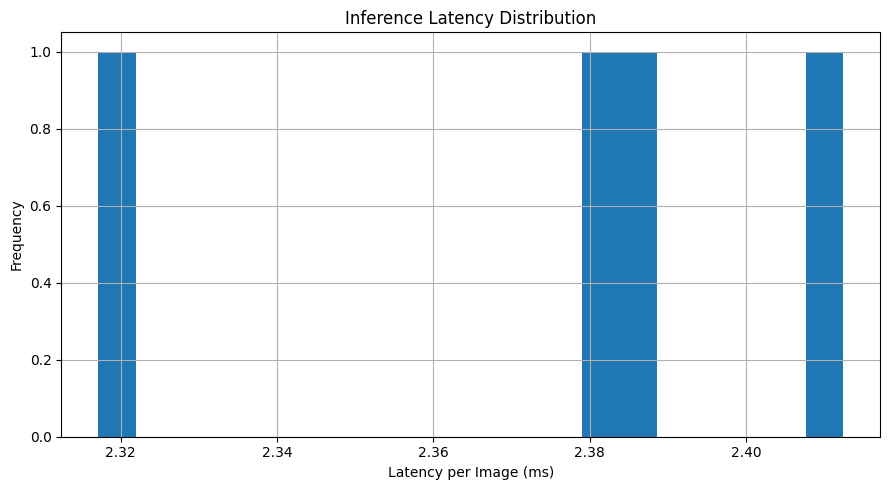

Average latency per image: 2.3741414062428134 ms
Latency graph saved successfully.


In [23]:
import time
import torch
import numpy as np
import matplotlib.pyplot as plt
import os

graphs_dir = os.path.join(project_dir, "graphs")
os.makedirs(graphs_dir, exist_ok=True)

model.eval()

image_latency_list = []

# Warm-up
with torch.inference_mode():
    for i, (images, labels, boxes) in enumerate(test_loader):
        images = images.to(device)
        _ = model(images)

        if i >= 2:
            break

# Measure latency
with torch.inference_mode():
    for images, labels, boxes in test_loader:

        images = images.to(device)

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        _ = model(images)

        if device.type == "cuda":
            torch.cuda.synchronize()

        end_time = time.perf_counter()

        batch_latency_ms = (end_time - start_time) * 1000

        batch_size = images.size(0)

        image_latency_list.append(
            batch_latency_ms / batch_size
        )

# Plot
plt.figure(figsize=(9, 5))

plt.hist(image_latency_list, bins=20)

plt.xlabel("Latency per Image (ms)")
plt.ylabel("Frequency")
plt.title("Inference Latency Distribution")

plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(graphs_dir, "inference_latency_distribution.png"),
    dpi=300
)

plt.show()

print("Average latency per image:",
      np.mean(image_latency_list), "ms")

print("Latency graph saved successfully.")

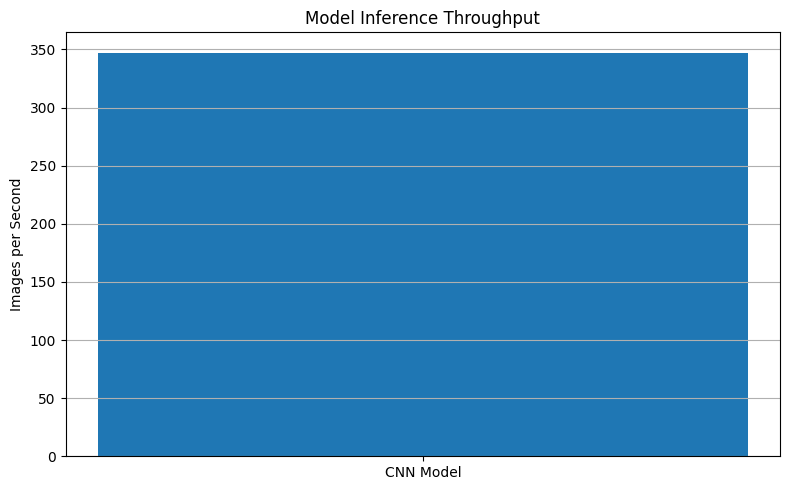

Total images: 100
Total time: 0.2879 seconds
Throughput: 347.34 images/second
Throughput graph saved successfully.


In [24]:
import time
import torch
import matplotlib.pyplot as plt
import os

graphs_dir = os.path.join(project_dir, "graphs")
os.makedirs(graphs_dir, exist_ok=True)

model.eval()

total_images = 0

if device.type == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

with torch.inference_mode():
    for images, labels, boxes in test_loader:

        images = images.to(device)

        _ = model(images)

        total_images += images.size(0)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.perf_counter()

total_time_seconds = end_time - start_time

throughput = total_images / total_time_seconds

# Plot throughput
plt.figure(figsize=(8, 5))

plt.bar(["CNN Model"], [throughput])

plt.ylabel("Images per Second")
plt.title("Model Inference Throughput")

plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    os.path.join(graphs_dir, "throughput_benchmark.png"),
    dpi=300
)

plt.show()

print(f"Total images: {total_images}")
print(f"Total time: {total_time_seconds:.4f} seconds")
print(f"Throughput: {throughput:.2f} images/second")
print("Throughput graph saved successfully.")

Metrics found: {'Accuracy': 0.99, 'Precision': 0.9901960784313726, 'Recall': 0.9895833333333334, 'F1-Score': 0.9897338703308852, 'mAP@0.50': 0.9867986798679867, 'mAP@0.75': 0.16901086590471048}


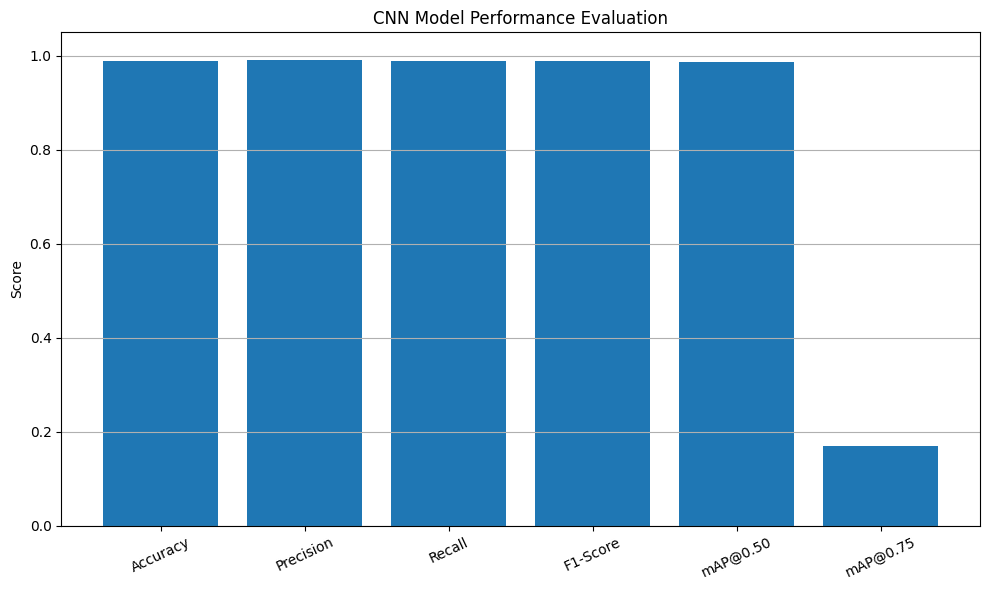

Performance comparison graph saved successfully.


In [25]:
import matplotlib.pyplot as plt
import os

graphs_dir = os.path.join(project_dir, "graphs")
os.makedirs(graphs_dir, exist_ok=True)

# Safely retrieve metrics from previous cells
def get_metric(possible_names):
    for name in possible_names:
        if name in globals():
            return float(globals()[name])
    return None

metric_values = {
    "Accuracy": get_metric(["accuracy"]),
    "Precision": get_metric(["precision", "macro_precision"]),
    "Recall": get_metric(["recall", "macro_recall"]),
    "F1-Score": get_metric(["f1", "f1_score", "macro_f1"]),
    "mAP@0.50": get_metric(["map_50", "mAP_50", "map50"]),
    "mAP@0.75": get_metric(["map_75", "mAP_75", "map75"])
}

# Keep only available metrics
available_metrics = {
    name: value
    for name, value in metric_values.items()
    if value is not None
}

print("Metrics found:", available_metrics)

if available_metrics:

    plt.figure(figsize=(10, 6))

    plt.bar(
        list(available_metrics.keys()),
        list(available_metrics.values())
    )

    plt.ylabel("Score")
    plt.title("CNN Model Performance Evaluation")

    plt.ylim(0, 1.05)
    plt.xticks(rotation=25)
    plt.grid(axis="y")
    plt.tight_layout()

    plt.savefig(
        os.path.join(graphs_dir, "model_performance_comparison.png"),
        dpi=300
    )

    plt.show()

    print("Performance comparison graph saved successfully.")

else:
    print("No metric variables found. Please rerun the evaluation cells.")

In [26]:
import json
import os
import torch
import numpy as np
from datetime import datetime

# Report folder
reports_dir = os.path.join(project_dir, "reports")
os.makedirs(reports_dir, exist_ok=True)

# Helper: find existing metric variables
def find_value(names):
    for name in names:
        if name in globals():
            value = globals()[name]

            if isinstance(value, (int, float, np.number)):
                return float(value)

    return None

# Classification metrics
classification_metrics = {
    "accuracy": find_value(["accuracy", "test_accuracy"]),
    "precision": find_value(["precision", "macro_precision"]),
    "recall": find_value(["recall", "macro_recall"]),
    "f1_score": find_value(["f1", "f1_score", "macro_f1"])
}

# Detection metrics
detection_metrics = {
    "mean_iou": find_value(["mean_iou", "average_iou"]),
    "mAP_50": find_value(["map_50", "mAP_50", "map50"]),
    "mAP_75": find_value(["map_75", "mAP_75", "map75"]),
    "mAP_50_95": find_value(["map_50_95", "mAP_50_95", "map50_95"])
}

# Latency
if "image_latency_list" in globals() and len(image_latency_list) > 0:
    average_image_latency = float(np.mean(image_latency_list))
else:
    average_image_latency = None

if "batch_latency_list" in globals() and len(batch_latency_list) > 0:
    average_batch_latency = float(np.mean(batch_latency_list))
else:
    average_batch_latency = None

latency_metrics = {
    "average_image_latency_ms": average_image_latency,
    "average_batch_latency_ms": average_batch_latency
}

# Throughput
throughput_metrics = {
    "images_per_second": find_value(["throughput"]),
    "total_inference_time_seconds": find_value(["total_time_seconds"])
}

# GPU memory information
gpu_memory_metrics = {
    "gpu_available": bool(torch.cuda.is_available()),
    "allocated_memory_mb": find_value(["allocated_memory"]),
    "reserved_memory_mb": find_value(["reserved_memory"]),
    "peak_allocated_memory_mb": find_value(["peak_allocated_memory"]),
    "peak_reserved_memory_mb": find_value(["peak_reserved_memory"])
}

# System information
system_information = {
    "device": str(device),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "GPU not available"
    ),
    "pytorch_version": torch.__version__
}

# Experiment configuration
experiment_configuration = {
    "model": "Custom CNN Detection Model",
    "image_size": 64,
    "number_of_classes": 3,
    "class_names": ["Person", "Car", "Bicycle"],
    "training_images": 500,
    "testing_images": 100,
    "batch_size": 32,
    "epochs": 15,
    "dataset_type": "Synthetic Object Detection Dataset",
    "objects_per_image": 1
}

# Combine all results
skill9_report = {
    "skill_name": "Skill 9 - Inference Baseline Measurement",
    "report_generated": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "system_information": system_information,
    "experiment_configuration": experiment_configuration,
    "classification_metrics": classification_metrics,
    "detection_metrics": detection_metrics,
    "latency_metrics": latency_metrics,
    "throughput_metrics": throughput_metrics,
    "gpu_memory_metrics": gpu_memory_metrics
}

# Save report
report_path = os.path.join(
    reports_dir,
    "skill9_evaluation_report.json"
)

with open(report_path, "w") as file:
    json.dump(skill9_report, file, indent=4)

print("=" * 50)
print("SKILL 9 JSON REPORT")
print("=" * 50)

print(json.dumps(skill9_report, indent=4))

print("\nReport saved successfully!")
print(report_path)

SKILL 9 JSON REPORT
{
    "skill_name": "Skill 9 - Inference Baseline Measurement",
    "report_generated": "2026-11-27 08:09:16",
    "system_information": {
        "device": "cpu",
        "gpu_name": "GPU not available",
        "pytorch_version": "2.14.1+cpu"
    },
    "experiment_configuration": {
        "model": "Custom CNN Detection Model",
        "image_size": 64,
        "number_of_classes": 3,
        "class_names": [
            "Person",
            "Car",
            "Bicycle"
        ],
        "training_images": 500,
        "testing_images": 100,
        "batch_size": 32,
        "epochs": 15,
        "dataset_type": "Synthetic Object Detection Dataset",
        "objects_per_image": 1
    },
    "classification_metrics": {
        "accuracy": 0.99,
        "precision": 0.9901960784313726,
        "recall": 0.9895833333333334,
        "f1_score": 0.9897338703308852
    },
    "detection_metrics": {
        "mean_iou": 0.7260434031486511,
        "mAP_50": 0.986798679

In [27]:
import os

print("=" * 60)
print("SKILL 9 PROJECT FILE VERIFICATION")
print("=" * 60)

for root, dirs, files in os.walk(project_dir):

    level = root.replace(project_dir, "").count(os.sep)

    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    sub_indent = "    " * (level + 1)

    for file in files:
        file_path = os.path.join(root, file)

        file_size = os.path.getsize(file_path) / 1024

        print(f"{sub_indent}{file} ({file_size:.2f} KB)")

print("\nProject directory verified.")

SKILL 9 PROJECT FILE VERIFICATION
Skill9_Inference_Baseline/
    data/
    reports/
        skill9_evaluation_report.json (1.53 KB)
    models/
        skill9_cnn_detection_model.pth (133.52 KB)
    results/
    graphs/
        throughput_benchmark.png (69.00 KB)
        inference_latency_distribution.png (71.06 KB)
        model_performance_comparison.png (110.79 KB)

Project directory verified.


In [28]:
import os

readme_content = """
# Skill 9: Inference Baseline Measurement

## Project Overview

This project evaluates a custom CNN object detection model using
classification accuracy, object localization metrics, inference latency,
throughput, and GPU memory measurements.

## Aim

To establish an inference performance baseline and evaluate the model's
accuracy, speed, efficiency, and resource usage.

## Objectives

- Evaluate classification performance.
- Calculate Precision, Recall, and F1-score.
- Evaluate object localization using Intersection over Union (IoU).
- Calculate simplified mAP at different IoU thresholds.
- Measure inference latency.
- Measure throughput in images per second.
- Measure GPU memory consumption when GPU is available.
- Generate performance visualization graphs.
- Save evaluation results in JSON format.

## Dataset

A synthetic object detection dataset was generated for experimentation.

- Training images: 500
- Testing images: 100
- Image size: 64 x 64
- Number of classes: 3
- Classes: Person, Car, Bicycle
- Objects per image: 1

## Model Architecture

Custom CNN Detection Model:

1. Convolution layer: 3 -> 16 channels
2. Convolution layer: 16 -> 32 channels
3. Convolution layer: 32 -> 64 channels
4. Adaptive Average Pooling
5. Shared fully connected layer
6. Classification head
7. Bounding box regression head

## Technologies Used

- Python
- PyTorch
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Evaluation Metrics

### Classification

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

### Object Detection

- Intersection over Union (IoU)
- Simplified mAP@0.50
- Simplified mAP@0.75
- Simplified mAP@0.50:0.95

### Performance

- Average inference latency
- Batch latency
- Throughput (images per second)
- GPU memory allocation

## Project Structure

Skill9_Inference_Baseline/
|
|-- data/
|-- models/
|   |-- skill9_cnn_detection_model.pth
|-- results/
|-- graphs/
|   |-- inference_latency_distribution.png
|   |-- throughput_benchmark.png
|   |-- model_performance_comparison.png
|-- reports/
|   |-- skill9_evaluation_report.json
|-- README.md

## Results

All experiment results are saved in:

reports/skill9_evaluation_report.json

Graphs are saved inside:

graphs/

## Important Limitations

This experiment uses a synthetic dataset and a custom CNN model.

The mAP calculation is a simplified educational implementation
for a single-object-per-image dataset. It is not equivalent to
the official COCO evaluation implementation.

Results should be interpreted as an experimental baseline and
not as production object detection benchmark results.

## Conclusion

This experiment established a baseline for model inference performance.
The CNN was evaluated for classification, localization, latency,
throughput, and memory usage. The generated graphs and JSON report
help analyze the trade-off between model accuracy and computational
performance.
"""

readme_path = os.path.join(project_dir, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README created successfully!")
print(readme_path)

print("\nREADME Preview:\n")
print(readme_content)

README created successfully!
/content/Skill9_Inference_Baseline/README.md

README Preview:


# Skill 9: Inference Baseline Measurement

## Project Overview

This project evaluates a custom CNN object detection model using
classification accuracy, object localization metrics, inference latency,
throughput, and GPU memory measurements.

## Aim

To establish an inference performance baseline and evaluate the model's
accuracy, speed, efficiency, and resource usage.

## Objectives

- Evaluate classification performance.
- Calculate Precision, Recall, and F1-score.
- Evaluate object localization using Intersection over Union (IoU).
- Calculate simplified mAP at different IoU thresholds.
- Measure inference latency.
- Measure throughput in images per second.
- Measure GPU memory consumption when GPU is available.
- Generate performance visualization graphs.
- Save evaluation results in JSON format.

## Dataset

A synthetic object detection dataset was generated for experimentation.

- Trainin

In [30]:
import os

project_dir = "/content/Skill9_Inference_Baseline"

print("Project folder exists:", os.path.exists(project_dir))

if os.path.exists(project_dir):
    print("\nProject contents:")
    for item in os.listdir(project_dir):
        print("-", item)
else:
    print("Project folder not found.")

Project folder exists: True

Project contents:
- data
- reports
- models
- results
- README.md
- graphs


In [31]:
import os
import shutil
from google.colab import files

project_dir = "/content/Skill9_Inference_Baseline"

# Recreate missing folders if needed
for folder in ["data", "models", "results", "graphs", "reports"]:
    os.makedirs(os.path.join(project_dir, folder), exist_ok=True)

# Ensure README exists
readme_path = os.path.join(project_dir, "README.md")

if not os.path.exists(readme_path):
    with open(readme_path, "w") as f:
        f.write("# Skill 9 - Inference Baseline Measurement\n\n")
        f.write("CNN evaluation: accuracy, mAP, latency, throughput and memory.")

# Create ZIP
zip_base = "/content/Skill9_Inference_Baseline_Submission"

zip_path = shutil.make_archive(
    zip_base,
    "zip",
    root_dir=project_dir
)

print("ZIP CREATED SUCCESSFULLY!")
print("File:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

# Download
files.download(zip_path)

ZIP CREATED SUCCESSFULLY!
File: /content/Skill9_Inference_Baseline_Submission.zip
Size: 0.29 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>